# Lateral position of the cells from the v4 tables (no videos needed)

This notebook only reads the tables that `cell_trajectory_morphology_thesis_v4` exported to its table folder:

* `detection_audit.csv.gz` (or `.csv`): every detection with centre, bounding box, image size, QC flags and `cell_uid`
* `cells_primary.csv`: the retained tracks (one row per cell) with velocity and deformation

No database and no video clips are needed. The channel walls are taken from one of these sources, per recording:

| `WALL_SOURCE` | walls | use when |
|---|---|---|
| `'image_edges'` | top and bottom image border | the image was cropped exactly to the channel |
| `'metadata'` | `channel_center_y_px` from the v4 metadata, width 40 µm | the channel centre was entered in `cell_analysis_metadata.csv` |
| `'envelope'` | outermost cell edges of all detections of the recording | the walls are inside the image and cells reach them |
| `'auto'` | `image_edges` if the image is at most about 1.3 channel widths high, otherwise `metadata` if available, otherwise `envelope` | default |

Section 3 prints the image height of every recording and the width between the walls that were used.
**Check this table before using the results.** If the width is clearly smaller than 40 µm with the envelope method,
the cells did not reach the walls, and only the spread of the positions is meaningful, not their offset from the axis.

Convention: flow along the image x axis. `y_rel_um` is the distance of the cell centre from the channel axis,
positive towards the top of the image.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 200)
print('Imports OK')

Imports OK


## 1. Settings
`V4_TABLE_DIR` is the folder in which v4 wrote `cells_primary.csv`, `detection_audit.csv.gz` and the other tables.

In [2]:
V4_TABLE_DIR = Path(r'/Volumes/Extreme SSD/Masterarbeit/Code/PC/cell_thesis_results_v4_2/run_20261012_125134_843989/tables')   # adjust
OUTPUT_DIR = Path('lateral_position_results')

WALL_SOURCE = 'auto'            # 'auto', 'image_edges', 'metadata', 'envelope'
MANUAL_WALLS_PX = {
    # ('20260921_NIH3T3_single', '20_10_BF'): (40.0, 83.0),   # (y_top, y_bottom) in px, overrides WALL_SOURCE
}
PIXEL_SIZE_UM = 0.925           # used when the table has no pixel size
CHANNEL_WIDTH_UM = 40.0
CHANNEL_HEIGHT_UM = 40.0
STREAM_HALF_WIDTH_UM = 4.7      # half of the expected sample-stream width (9.4 um)
EXCLUDED_FLOW_RATES = [600.0]
ENVELOPE_QUANTILE = 0.002       # outermost 0.2 % of the cell edges define the walls (robust against outliers)
N_X_SEGMENTS = 3                # envelope in 3 segments along x to correct a tilt
POOL_ENVELOPE_BY_EXPERIMENT = False   # True: one envelope per day, if chip and camera were not moved between flow rates

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / 'figures').mkdir(exist_ok=True)

## 2. Load the v4 tables

In [3]:
def find_table(name):
    for suffix in ['.csv.gz', '.csv']:
        p = V4_TABLE_DIR / (name + suffix)
        if p.is_file():
            return p
    raise FileNotFoundError(V4_TABLE_DIR / (name + '.csv(.gz)'))

cells = pd.read_csv(find_table('cells_primary'))
cells = cells.loc[~cells.flow_rate_ul_min.isin(EXCLUDED_FLOW_RATES)]

wanted = ['cell_uid', 'experiment_id', 'cell_type', 'folder', 'video', 'frame', 'imaging_mode', 'flow_rate_ul_min',
          'centroid_x_px', 'centroid_y_px', 'bbox_x0', 'bbox_y0', 'bbox_x1', 'bbox_y1', 'height_px', 'width_px',
          'pixel_size_um', 'channel_center_y_px', 'point_qc_ok', 'status', 'track_retained', 'experiment_excluded']
path = find_table('detection_audit')
header = pd.read_csv(path, nrows=0).columns
det = pd.read_csv(path, usecols=[c for c in wanted if c in header], low_memory=False)
missing = [c for c in ['centroid_x_px', 'centroid_y_px', 'bbox_y0', 'bbox_y1', 'height_px', 'cell_uid'] if c not in det]
if missing:
    raise KeyError(f'detection_audit has no columns {missing}')
if 'pixel_size_um' not in det:
    det['pixel_size_um'] = PIXEL_SIZE_UM
det['pixel_size_um'] = pd.to_numeric(det.pixel_size_um, errors='coerce').fillna(PIXEL_SIZE_UM)
det = det.loc[~det.flow_rate_ul_min.isin(EXCLUDED_FLOW_RATES)]
if 'experiment_excluded' in det:
    det = det.loc[~det.experiment_excluded.astype(bool)]
print(f'{len(cells):,} retained tracks, {len(det):,} detections')

12,599 retained tracks, 481,372 detections


## 3. Walls per recording (check this table)

In [4]:
def envelope(sub, h_px):
    # Outermost cell edges along y, in N_X_SEGMENTS segments along x.
    edges = np.linspace(sub.centroid_x_px.min(), sub.centroid_x_px.max() + 1e-9, N_X_SEGMENTS + 1)
    xs, tops, bots = [], [], []
    for a, b in zip(edges[:-1], edges[1:]):
        s = sub.loc[sub.centroid_x_px.between(a, b)]
        if len(s) < 50:
            continue
        xs.append((a + b) / 2)
        tops.append(s.bbox_y0.quantile(ENVELOPE_QUANTILE))
        bots.append(s.bbox_y1.quantile(1 - ENVELOPE_QUANTILE))
    if not xs:
        return None
    xs, tops, bots = map(np.asarray, (xs, tops, bots))
    c = (tops + bots) / 2
    slope, icpt = np.polyfit(xs, c, 1) if len(xs) > 1 else (0.0, c[0])
    return dict(y_top_px=float(np.median(tops)), y_bottom_px=float(np.median(bots)),
                centre_intercept_px=float(icpt), centre_slope=float(slope), n_detections_envelope=int(len(sub)))

# all accepted detections (also those not on a retained track) define the envelope
src = det.loc[det.status.eq('accepted')] if 'status' in det else det
keys = ['experiment_id', 'folder']
rec = (det.groupby(keys).agg(cell_type=('cell_type', 'first'), imaging_mode=('imaging_mode', 'first'),
                             flow_rate_ul_min=('flow_rate_ul_min', 'first'), height_px=('height_px', 'median'),
                             width_px=('width_px', 'median') if 'width_px' in det else ('height_px', 'size'),
                             pixel_size_um=('pixel_size_um', 'median'),
                             channel_center_y_px=('channel_center_y_px', 'median') if 'channel_center_y_px' in det
                             else ('height_px', lambda s: np.nan)).reset_index())
rec['height_um'] = rec.height_px * rec.pixel_size_um

rows = []
for r in rec.itertuples():
    key = (r.experiment_id, r.folder)
    h = float(r.height_px)
    method = WALL_SOURCE
    if key in MANUAL_WALLS_PX:
        method = 'manual'
    elif WALL_SOURCE == 'auto':
        if r.height_um <= 1.3 * CHANNEL_WIDTH_UM:
            method = 'image_edges'
        elif np.isfinite(r.channel_center_y_px):
            method = 'metadata'
        else:
            method = 'envelope'
    res = None
    if method == 'manual':
        t, b = MANUAL_WALLS_PX[key]
        res = dict(y_top_px=t, y_bottom_px=b, centre_intercept_px=(t + b) / 2, centre_slope=0.0)
    elif method == 'image_edges':
        res = dict(y_top_px=0.0, y_bottom_px=h, centre_intercept_px=h / 2, centre_slope=0.0)
    elif method == 'metadata':
        half = CHANNEL_WIDTH_UM / 2 / r.pixel_size_um
        res = dict(y_top_px=r.channel_center_y_px - half, y_bottom_px=r.channel_center_y_px + half,
                   centre_intercept_px=float(r.channel_center_y_px), centre_slope=0.0)
    else:
        pool = src.loc[src.experiment_id.eq(r.experiment_id)] if POOL_ENVELOPE_BY_EXPERIMENT else \
               src.loc[src.experiment_id.eq(r.experiment_id) & src.folder.eq(r.folder)]
        res = envelope(pool, h)
        if res is None:
            method, res = 'image_edges (too few detections)', dict(y_top_px=0.0, y_bottom_px=h,
                                                                  centre_intercept_px=h / 2, centre_slope=0.0)
    res.update(experiment_id=r.experiment_id, folder=r.folder, method=method)
    res['wall_distance_um'] = (res['y_bottom_px'] - res['y_top_px']) * r.pixel_size_um
    rows.append(res)

walls = rec.merge(pd.DataFrame(rows), on=keys)
walls['reaches_walls'] = (walls.wall_distance_um >= 0.85 * CHANNEL_WIDTH_UM) & (walls.wall_distance_um <= 1.15 * CHANNEL_WIDTH_UM)
walls.to_csv(OUTPUT_DIR / 'walls_per_recording.csv', index=False)
display(walls[['experiment_id', 'folder', 'height_px', 'height_um', 'method', 'y_top_px', 'y_bottom_px',
               'centre_slope', 'wall_distance_um', 'reaches_walls']].round(2))
if not walls.reaches_walls.all():
    print('NOTE: for recordings with reaches_walls = False, the wall distance is not about 40 um. '
          'Only the spread of the lateral positions is meaningful there, not the offset from the axis.')

,experiment_id,folder,height_px,height_um,method,y_top_px,y_bottom_px,centre_slope,wall_distance_um,reaches_walls
0,20260921_NIH3T3_single,100_50_BF,128.0,118.4,envelope,61.34,102.00,-0.06,37.61,True
1,20260921_NIH3T3_single,100_50_Ph2,128.0,118.4,envelope,64.23,100.00,-0.06,33.08,False
2,20260921_NIH3T3_single,200_100_BF,128.0,118.4,envelope,58.98,101.01,-0.06,38.87,True
3,20260921_NIH3T3_single,200_100_Ph2,128.0,118.4,envelope,63.00,100.00,-0.06,34.22,True
4,20260921_NIH3T3_single,20_10_BF,128.0,118.4,envelope,54.00,96.00,-0.05,38.85,True
5,20260921_NIH3T3_single,20_10_Ph2,128.0,118.4,envelope,58.00,100.00,-0.06,38.85,True
6,20260922_HeLa_single,100_50_BF,128.0,118.4,envelope,51.00,94.00,-0.03,39.78,True
7,20260922_HeLa_single,100_50_Ph2,128.0,118.4,envelope,53.00,94.00,-0.03,37.93,True
8,20260922_HeLa_single,200_100_BF,128.0,118.4,envelope,52.00,91.00,-0.03,36.08,True
9,20260922_HeLa_single,200_100_Ph2,128.0,118.4,image_edges (too few detections),0.00,128.00,0.00,118.40,False


NOTE: for recordings with reaches_walls = False, the wall distance is not about 40 um. Only the spread of the lateral positions is meaningful there, not the offset from the axis.


## 4. Lateral position per retained track

In [5]:
d = det.loc[det.cell_uid.isin(cells.cell_uid)]
if 'point_qc_ok' in d:
    d = d.loc[d.point_qc_ok.astype(bool)]
d = d.merge(walls[keys + ['centre_intercept_px', 'centre_slope', 'y_top_px', 'y_bottom_px', 'method', 'reaches_walls']],
            on=keys, how='left')
d['y_rel_um'] = (d.centre_intercept_px + d.centre_slope * d.centroid_x_px - d.centroid_y_px) * d.pixel_size_um
pos = d.groupby('cell_uid').agg(y_rel_um=('y_rel_um', 'median'), y_rel_sd_um=('y_rel_um', 'std'),
                                n_det_position=('y_rel_um', 'size')).reset_index()
tracks = cells.merge(pos, on='cell_uid', how='inner').merge(walls[keys + ['method', 'reaches_walls']], on=keys, how='left')
tracks['abs_y_um'] = tracks.y_rel_um.abs()
tracks['max_possible_um'] = CHANNEL_WIDTH_UM / 2 - tracks.equivalent_diameter_um / 2
tracks.to_csv(OUTPUT_DIR / 'lateral_position_tracks.csv', index=False)
print(f'{len(tracks):,} of {len(cells):,} retained tracks have a lateral position')

12,599 of 12,599 retained tracks have a lateral position


## 5. Summary per cell line, imaging mode and flow rate
`iqr_um` and `sd_um` describe how narrowly the cells are focused. `median_um` and `frac_in_stream` (centre within ±4.7 µm
of the axis) are only meaningful where `reaches_walls` is True or the walls are the image edges.

In [6]:
GROUPS = ['cell_type', 'imaging_mode', 'flow_rate_ul_min']
q = lambda p: (lambda s: s.quantile(p))
summary = tracks.groupby(GROUPS).agg(
    n_tracks=('y_rel_um', 'size'), median_um=('y_rel_um', 'median'), q25_um=('y_rel_um', q(.25)),
    q75_um=('y_rel_um', q(.75)), sd_um=('y_rel_um', 'std'), p05_um=('y_rel_um', q(.05)), p95_um=('y_rel_um', q(.95)),
    frac_in_stream=('abs_y_um', lambda s: (s <= STREAM_HALF_WIDTH_UM).mean()),
    wall_method=('method', 'first'), reaches_walls=('reaches_walls', 'all')).reset_index()
summary['iqr_um'] = summary.q75_um - summary.q25_um
imp = tracks.assign(i=tracks.abs_y_um > tracks.max_possible_um).groupby(GROUPS).i.mean()
summary['frac_impossible'] = summary.set_index(GROUPS).index.map(imp)
summary.to_csv(OUTPUT_DIR / 'lateral_position_summary.csv', index=False)
display(summary.round(3))

,cell_type,imaging_mode,flow_rate_ul_min,n_tracks,median_um,q25_um,q75_um,sd_um,p05_um,p95_um,frac_in_stream,wall_method,reaches_walls,iqr_um,frac_impossible
0,HeLa,BF,30,12,-1.807,-4.133,-1.198,3.118,-4.391,2.778,0.917,envelope,False,2.935,0.000
1,HeLa,BF,150,298,-4.908,-6.861,-2.773,3.574,-8.017,3.749,0.436,envelope,True,4.088,0.000
2,HeLa,BF,300,61,-3.605,-5.138,-0.227,3.860,-7.776,4.276,0.639,envelope,True,4.911,0.000
3,HeLa,Ph2,30,2632,-6.054,-7.324,2.305,6.219,-8.489,8.860,0.165,envelope,True,9.630,0.001
4,HeLa,Ph2,150,88,-3.614,-6.365,1.484,5.028,-9.149,7.344,0.477,envelope,True,7.850,0.000
5,HeLa,Ph2,300,1,-8.451,-8.451,-8.451,NaN,-8.451,-8.451,0.000,image_edges (too few detections),False,0.000,0.000
6,NIH3T3,BF,30,3161,-1.009,-1.816,0.468,2.232,-3.133,3.474,0.949,envelope,True,2.284,0.001
7,NIH3T3,BF,150,990,-0.197,-1.121,2.311,2.315,-2.877,4.408,0.961,envelope,True,3.431,0.000
8,NIH3T3,BF,300,137,0.925,-0.156,2.358,2.609,-2.018,5.506,0.920,envelope,True,2.514,0.007
9,NIH3T3,Ph2,30,3806,0.270,-0.961,1.809,2.718,-3.703,5.050,0.901,envelope,True,2.771,0.001


## 6. Histograms

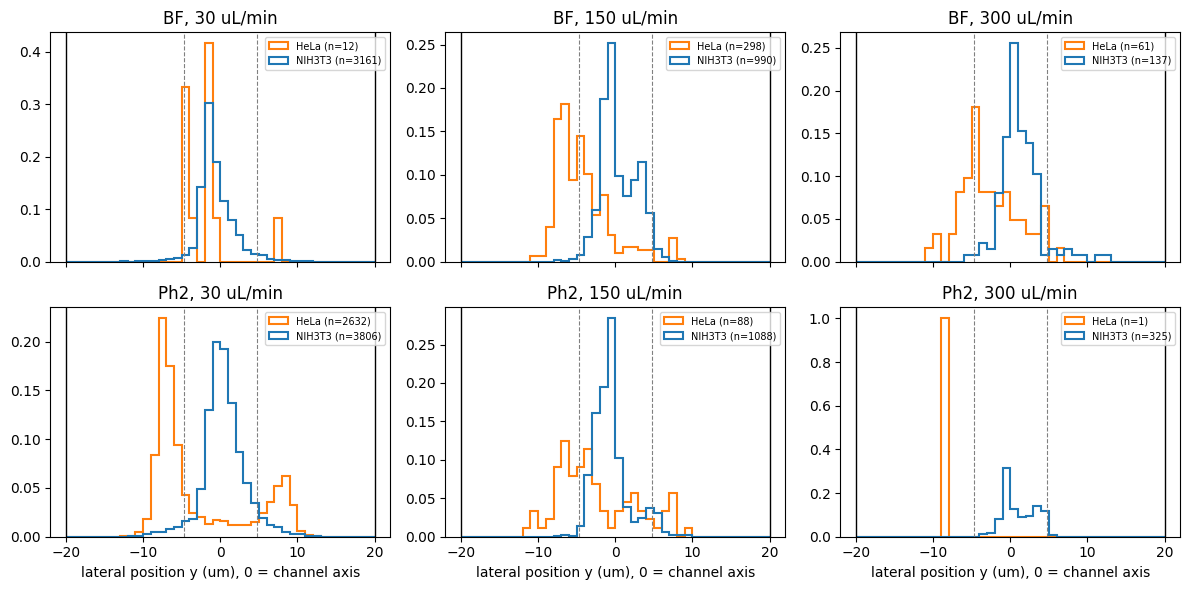

In [7]:
modes = [m for m in ['BF', 'Ph2'] if m in set(tracks.imaging_mode)]
flows = sorted(tracks.flow_rate_ul_min.unique())
colors = {'HeLa': 'tab:orange', 'NIH3T3': 'tab:blue'}
bins = np.arange(-CHANNEL_WIDTH_UM / 2, CHANNEL_WIDTH_UM / 2 + 1, 1.0)
fig, axes = plt.subplots(len(modes), len(flows), figsize=(4 * len(flows), 3 * len(modes)), sharex=True, squeeze=False)
for i, m in enumerate(modes):
    for j, f in enumerate(flows):
        ax = axes[i, j]
        for ct, g in tracks.loc[(tracks.imaging_mode == m) & (tracks.flow_rate_ul_min == f)].groupby('cell_type'):
            ax.hist(g.y_rel_um, bins=bins, density=True, histtype='step', lw=1.5, color=colors.get(ct),
                    label=f'{ct} (n={len(g)})')
        for x in (-STREAM_HALF_WIDTH_UM, STREAM_HALF_WIDTH_UM):
            ax.axvline(x, color='grey', ls='--', lw=0.8)
        for x in (-CHANNEL_WIDTH_UM / 2, CHANNEL_WIDTH_UM / 2):
            ax.axvline(x, color='k', lw=1)
        ax.set_title(f'{m}, {f:g} uL/min')
        if ax.get_legend_handles_labels()[0]:
            ax.legend(fontsize=7)
        if i == len(modes) - 1:
            ax.set_xlabel('lateral position y (um), 0 = channel axis')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'figures' / 'lateral_position_histograms.pdf'); plt.show()

## 7. Velocity and deformation against the lateral position
Lines: fluid velocity $u(y,z)/U$ of fully developed flow in the square channel in the mid-plane and in planes
8 and 14 µm from it.

check: centreline u_max/U = 2.096


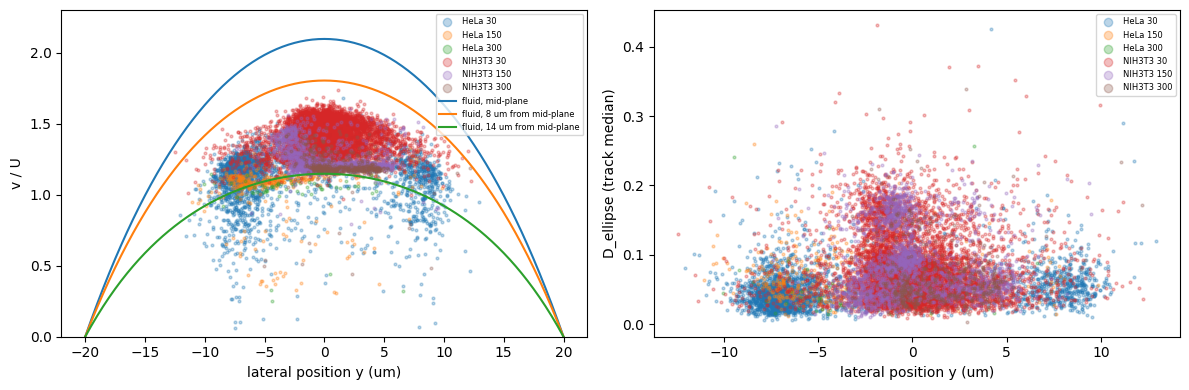

n  spearman_absY_vs_v  spearman_absY_vs_D
cell_type imaging_mode flow_rate_ul_min                                                
HeLa      BF           30                  12.0              -0.182               0.587
                       150                298.0              -0.237               0.002
                       300                 61.0              -0.030               0.115
          Ph2          30                2632.0              -0.258              -0.009
                       150                 88.0               0.259               0.139
                       300                  1.0                 NaN                 NaN
NIH3T3    BF           30                3161.0              -0.158               0.080
                       150                990.0               0.277              -0.210
                       300                137.0               0.091              -0.020
          Ph2          30                3806.0              -0.173              -0.033
                       150               1088.0               0.477              -0.498
                       300                325.0              -0.061               0.213

In [8]:
def rect_velocity_ratio(y_um, z_um, w=CHANNEL_WIDTH_UM, h=CHANNEL_HEIGHT_UM, n_terms=101):
    def u(yv, zv):
        s = 0.0
        for n in range(1, 2 * n_terms, 2):
            s = s + (1 / n**3) * (1 - np.cosh(n * np.pi * yv / h) / np.cosh(n * np.pi * w / (2 * h))) * np.sin(n * np.pi * zv / h)
        return s
    yy = ((np.arange(400) + 0.5) / 400 * w - w / 2)[:, None]; zz = ((np.arange(400) + 0.5) / 400 * h)[None, :]
    return u(np.asarray(y_um, float)[:, None], np.asarray(z_um, float)[None, :]) / u(yy, zz).mean()

yg = np.linspace(-CHANNEL_WIDTH_UM / 2, CHANNEL_WIDTH_UM / 2, 161)
print('check: centreline u_max/U =', round(float(rect_velocity_ratio([0], [CHANNEL_HEIGHT_UM / 2])[0, 0]), 3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (ct, f), g in tracks.groupby(['cell_type', 'flow_rate_ul_min']):
    axes[0].scatter(g.y_rel_um, g.cell_to_bulk_speed_ratio, s=4, alpha=0.3, label=f'{ct} {f:g}')
    axes[1].scatter(g.y_rel_um, g.deformation, s=4, alpha=0.3, label=f'{ct} {f:g}')
for lab, dz in [('fluid, mid-plane', 0), ('fluid, 8 um from mid-plane', 8), ('fluid, 14 um from mid-plane', 14)]:
    axes[0].plot(yg, rect_velocity_ratio(yg, [CHANNEL_HEIGHT_UM / 2 + dz])[:, 0], lw=1.5, label=lab)
axes[0].set(xlabel='lateral position y (um)', ylabel='v / U', ylim=(0, 2.3))
axes[1].set(xlabel='lateral position y (um)', ylabel='D_ellipse (track median)')
for a in axes:
    a.legend(fontsize=6, markerscale=3)
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'figures' / 'velocity_deformation_vs_position.pdf'); plt.show()

corr = tracks.groupby(GROUPS).apply(lambda g: pd.Series({
    'n': len(g), 'spearman_absY_vs_v': g.abs_y_um.corr(g.cell_to_bulk_speed_ratio, method='spearman'),
    'spearman_absY_vs_D': g.abs_y_um.corr(g.deformation, method='spearman')}), include_groups=False)
corr.to_csv(OUTPUT_DIR / 'lateral_position_correlations.csv')
display(corr.round(3))

## 8. Notes
* v4 removes detections whose bounding box touches the image border. If the walls are the image borders,
  cells touching a wall are missing.
* With the envelope method, the walls are where the outermost cells were. If no cell reached a wall, the wall
  distance is too small (`reaches_walls = False`), and the absolute offset from the axis is not measured.
* The position over the channel depth cannot be measured from the top view.
* Send me `walls_per_recording.csv`, `lateral_position_summary.csv`, `lateral_position_correlations.csv` and the two figures.